# Lab 8 — Morphological Image Processing


---
## Theory — What is morphological processing?

**Morpholgical Processing** is modifying and improving the shapes in an image.

 The two ingredients of every morphological operation:

1. **The image** — a binary image where white (`255`) pixels are *foreground* (the object) and black (`0`) pixels are *background*.
2. **The structuring element** (also called *kernel* or *probe*) — a small shape (e.g., 3×3 square, 5×5 circle) that you slide across the image.

### The four basic operations
<img src="https://drive.google.com/thumbnail?id=129tujHkYNk3b8US7HEqbt-WymOZgwMnA&sz=w1000" width="600">



| Operation | What it does | Formula | Effect on objects |
|---|---|---|---|
| **Erosion** | Shrinks objects | $A \ominus B$ | Removes thin parts and noise |
| **Dilation** | Grows objects | $A \oplus B$ | Fills gaps, thickens objects |
| **Opening** | Erosion then dilation | $A \circ B = (A \ominus B) \oplus B$ | Removes small noise but keeps overall size |
| **Closing** | Dilation then erosion | $A \bullet B = (A \oplus B) \ominus B$ | Fills small holes but keeps overall size |

### How to remember each one

- **Erosion eats away** at object edges → output is smaller.
- **Dilation expands** object edges → output is larger.
- **Opening = "open up" the gaps** between separated noise specks (removes noise without shrinking real objects).
- **Closing = "close up" small holes** inside objects (fills gaps without growing real objects).



---
## Task 1 — Create a Binary Image with Shapes and Noise

The lab provides this code to generate a synthetic test image with **4 shapes** and some random **salt noise**:
- A solid filled circle on the left
- A solid filled rectangle
- A hollow (outline-only) circle
- A hollow rectangle
- Plus 1000 random scattered white pixels (noise)

## Setup — Import libraries

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

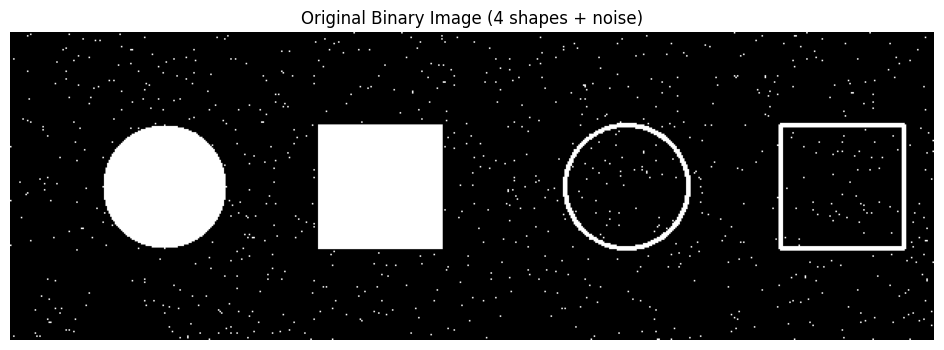

In [2]:
# Create a binary image with shapes and noise
image = np.zeros((200, 600), dtype=np.uint8)
cv2.circle(image, (100, 100), 40, 255, -1)              # Solid circle (filled) - radius=40
cv2.rectangle(image, (200, 60), (280, 140), 255, -1)    # Solid rectangle (filled) - start & end points= (200, 60), (280, 140)
cv2.circle(image, (400, 100), 40, 255, 2)               # Hollow circle (outline)
cv2.rectangle(image, (500, 60), (580, 140), 255, 2)     # Hollow rectangle (outline)

# Add small noise (1000 random white pixels)
np.random.seed(0)
for _ in range(1000):
    x, y = np.random.randint(0, 600), np.random.randint(0, 200)
    image[y, x] = 255

plt.figure(figsize=(12, 4))
plt.imshow(image, cmap='gray')
plt.title('Original Binary Image (4 shapes + noise)')
plt.axis('off')
plt.show()

---
Define the Structuring Element (5×5 Square Kernel)

The structuring element is the "shape" we slide across the image. The simplest one is a **square of all ones**:

$$K = \begin{bmatrix} 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \\ 1 & 1 & 1 & 1 & 1 \end{bmatrix}$$

**Why a square?** It's directionally neutral (same effect horizontally and vertically) and fast to compute. The `1`s indicate which positions in the neighborhood are "active" — for a square kernel, every neighbor counts.

In [3]:
kernel = np.ones((5, 5), np.uint8)
print("Square kernel (5×5):")
print(kernel)

Square kernel (5×5):
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]


---
## Assessment Task 1 — Apply Erosion, Dilation, Opening, Closing (Square Kernel)

For each operation we use a single OpenCV function:

| Operation | OpenCV call |
|---|---|
| Erosion | `cv2.erode(image, kernel, iterations=1)` |
| Dilation | `cv2.dilate(image, kernel, iterations=1)` |
| Opening | `cv2.morphologyEx(image, cv2.MORPH_OPEN, kernel)` |
| Closing | `cv2.morphologyEx(image, cv2.MORPH_CLOSE, kernel)` |



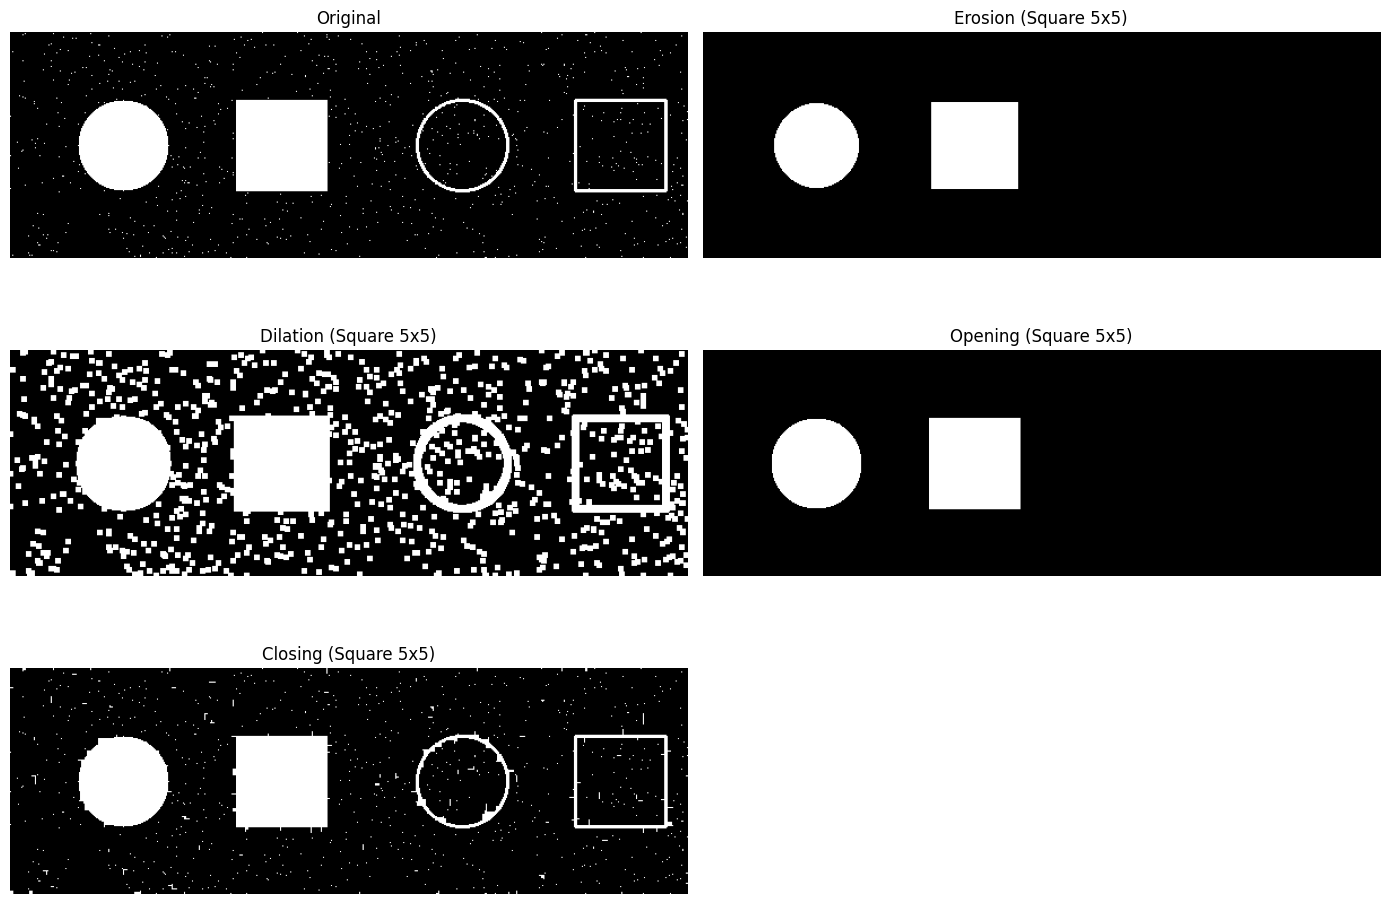

In [4]:
# Assessment Task 1 — Square kernel (5x5)
erosion  = cv2.erode(image, kernel, iterations=1)
dilation = cv2.dilate(image, kernel, iterations=1)
opening  = cv2.morphologyEx(image, cv2.MORPH_OPEN, kernel)
closing  = cv2.morphologyEx(image, cv2.MORPH_CLOSE, kernel)

titles = ['Original', 'Erosion', 'Dilation', 'Opening', 'Closing']
images = [image, erosion, dilation, opening, closing]

plt.figure(figsize=(14, 10))
for i, (t, im) in enumerate(zip(titles, images)):
    plt.subplot(3, 2, i + 1)
    plt.imshow(im, cmap='gray')
    plt.title(t + (' (Square 5x5)' if i else ''))
    plt.axis('off')
plt.tight_layout()
plt.show()

## Assessment Task 2 — Repeat with a Circular Kernel

Apply erosion, dilation opening and closing to the generated image in Task#1 using the following structuring element:

[[0 0 0 0 0 1 0 0 0 0 0]
 [0 0 1 1 1 1 1 1 1 0 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [1 1 1 1 1 1 1 1 1 1 1]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 1 1 1 1 1 1 1 1 1 0]
 [0 0 1 1 1 1 1 1 1 0 0]
 [0 0 0 0 0 1 0 0 0 0 0]]


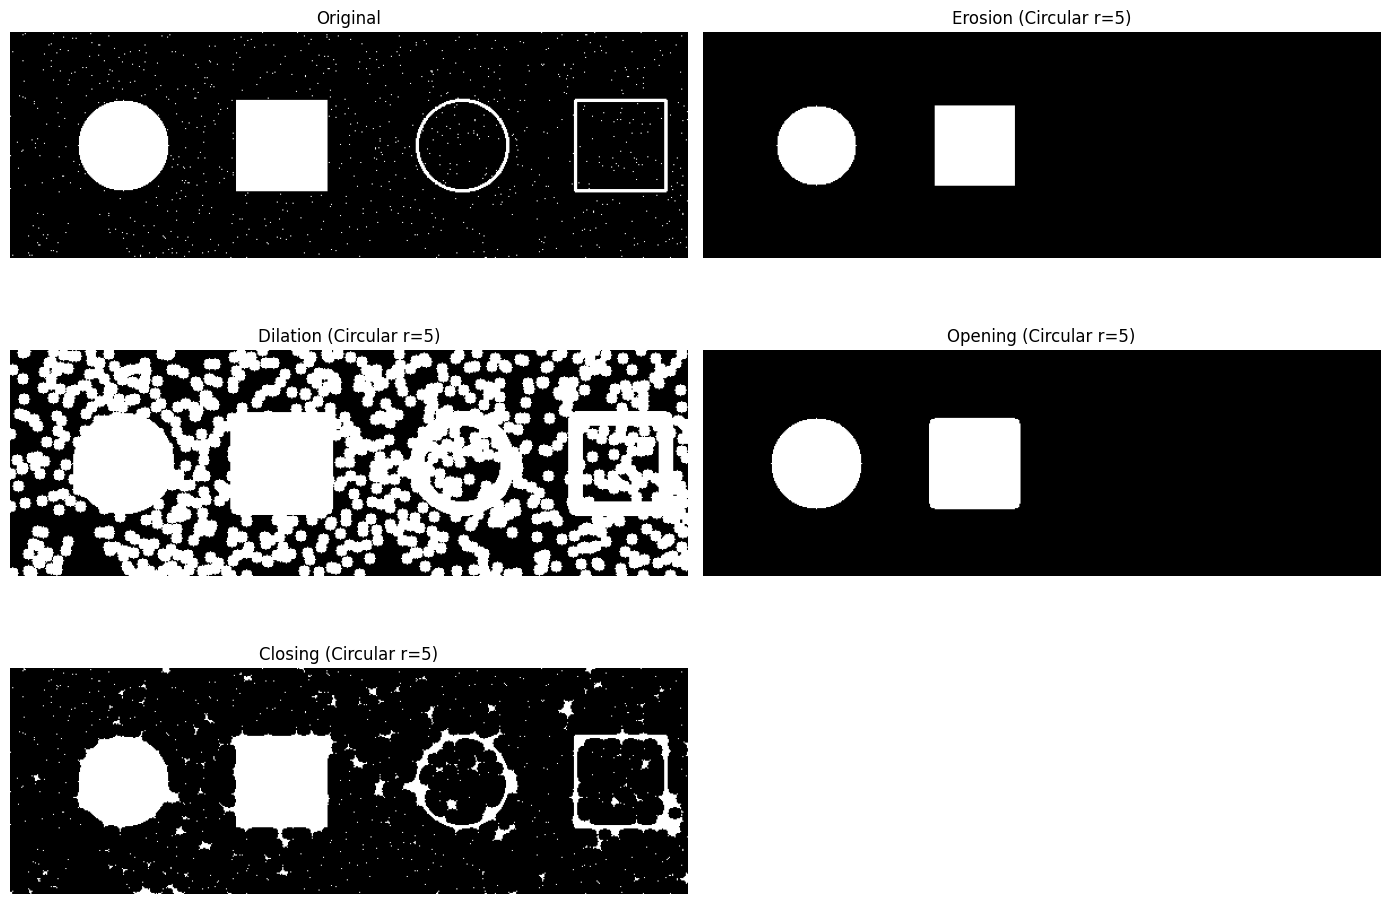

In [5]:
def circular_structuring_element(radius):
    """Creates a binary circular structuring element (exact circle)"""
    size = 2 * radius + 1                    # Ensure kernel size is odd
    kernel = np.zeros((size, size), dtype=np.uint8)
    cv2.circle(kernel, (radius, radius), radius, 1, -1)  # Draw filled circle
    return kernel

# Define radius
radius = 5
circle_kernel = circular_structuring_element(radius)

# Assessment Task 2 — Circular kernel
print(circle_kernel)

erosion_c  = cv2.erode(image, circle_kernel, iterations=1)
dilation_c = cv2.dilate(image, circle_kernel, iterations=1)
opening_c  = cv2.morphologyEx(image, cv2.MORPH_OPEN, circle_kernel)
closing_c  = cv2.morphologyEx(image, cv2.MORPH_CLOSE, circle_kernel)

titles = ['Original', 'Erosion', 'Dilation', 'Opening', 'Closing']
images = [image, erosion_c, dilation_c, opening_c, closing_c]

plt.figure(figsize=(14, 10))
for i, (t, im) in enumerate(zip(titles, images)):
    plt.subplot(3, 2, i + 1)
    plt.imshow(im, cmap='gray')
    plt.title(t + (' (Circular r=5)' if i else ''))
    plt.axis('off')
plt.tight_layout()
plt.show()

## Assessment Task 3 — Difference Between Square vs Circular Kernel

 In your own words, explain the difference between the results in Task#1 and Task#2



**Answer — Square (5×5) vs Circular (r = 5) kernel**

- **Shape of the results:** The square kernel keeps the sharp corners of the rectangle, because its shape matches the rectangle's edges. The circular kernel rounds the corners of the rectangle after dilation and opening, because a round probe cannot fit into a sharp 90° corner. The circle stays almost the same with both kernels.
- **Noise removal:** Erosion and opening remove the 1-pixel noise and the thin hollow outlines (thickness 2) with both kernels, and only the solid circle and solid rectangle remain. Opening with the circular kernel gives smoother, rounder objects.
- **Dilation:** The square kernel turns each noise pixel into a small square block. The circular kernel turns it into a round dot, and since the circular kernel is bigger (11×11 compared to 5×5) the dots are larger and merge with each other and with the shapes.
- **Closing:** With the square kernel the shapes mostly stay unchanged. With the circular kernel the closing merges many noise dots into blobs and clumps around the shapes, because the kernel is larger.
- **Conclusion:** The square kernel is directionally biased toward horizontal and vertical lines, so it preserves rectangular shapes and gives blocky results. The circular kernel treats all directions equally, so it gives smoother, more natural shapes but rounds sharp corners. The size of the structuring element also matters: the bigger the kernel, the stronger the effect.